# BÀI 6 (TRANG 27): PHÂN LỚP DỮ LIỆU MUSHROOM
- **Sinh viên thực hiện:** Dương Đại Phát
- **MSSV:** 6451071058
- **Nguồn dataset:** Google Drive (`mushrooms.csv`)

In [1]:
print("Dương Đại Phát - 6451071058")
import os
import subprocess
import sys

files_to_download = {
    "mushrooms.csv": "11OXFpnwUwK_Ka9BFmboMoT9RhTRe3CFW",
}
for fname, fid in files_to_download.items():
    if not os.path.exists(fname):
        subprocess.check_call([sys.executable, "-m", "gdown", f"https://drive.google.com/uc?id={fid}", "-O", fname])

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import tree, metrics
from sklearn.naive_bayes import GaussianNB

data = pd.read_csv('mushrooms.csv')
print("Kích thước dữ liệu:", data.shape)
data.info()

Dương Đại Phát - 6451071058


Kích thước dữ liệu: (8124, 23)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   object
 12  stalk-surface-above-ring  8124 non-null   object
 13  stalk-surface-below-ring  8124 non-null   objec

## Câu 4: Tách `features` và `labels` (`class`)

In [2]:
print("Dương Đại Phát - 6451071058")
features = data.drop('class', axis=1)
labels = data['class']
print("Features shape:", features.shape)
print("Phân bố nhãn class (e=edible, p=poisonous):\n", labels.value_counts())

Dương Đại Phát - 6451071058
Features shape: (8124, 22)
Phân bố nhãn class (e=edible, p=poisonous):
 class
e    4208
p    3916
Name: count, dtype: int64


## Câu 5: Chuyển đổi các cột phân loại về dạng one-hot vector

In [3]:
print("Dương Đại Phát - 6451071058")
non_numeric_cols = features.select_dtypes(exclude=['int64', 'float64']).columns
print("Số cột phân loại cần one-hot:", len(non_numeric_cols))
features_onehot = pd.get_dummies(features, columns=non_numeric_cols, dtype=int)
print("Kích thước sau one-hot:", features_onehot.shape)
features_onehot.head()

Dương Đại Phát - 6451071058
Số cột phân loại cần one-hot: 22
Kích thước sau one-hot: (8124, 117)


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,0,0,0,0,0,1,0,0,1,0,...,1,0,0,0,0,0,0,0,1,0
1,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
2,1,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0
3,0,0,0,0,0,1,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0


## Câu 6: Chia dữ liệu thành tập huấn luyện 70% và kiểm thử 30%

In [4]:
print("Dương Đại Phát - 6451071058")
X_train, X_test, y_train, y_test = train_test_split(features_onehot, labels, test_size=0.3, random_state=42)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

Dương Đại Phát - 6451071058
X_train: (5686, 117) | X_test: (2438, 117)


## Câu 7: Xây dựng cây quyết định ID3 (`criterion='entropy'`)

Dương Đại Phát - 6451071058
ID3 Accuracy: 1.0
Report:
               precision    recall  f1-score   support

           e       1.00      1.00      1.00      1257
           p       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



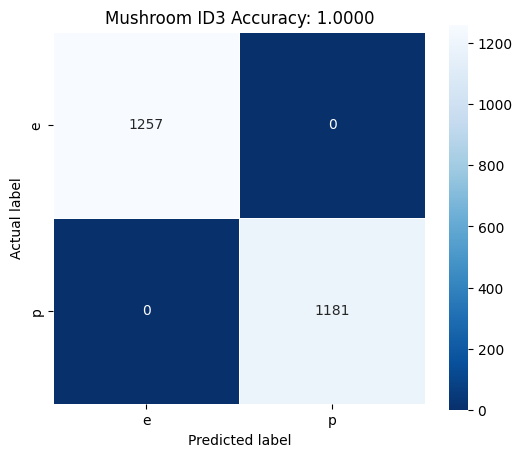

In [5]:
print("Dương Đại Phát - 6451071058")
clf_id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
clf_id3.fit(X_train, y_train)
id3_pred = clf_id3.predict(X_test)

id3_score = metrics.accuracy_score(y_test, id3_pred)
print("ID3 Accuracy:", id3_score)
print("Report:\n", metrics.classification_report(y_test, id3_pred))

id3_cm = metrics.confusion_matrix(y_test, id3_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(id3_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Blues_r',
            xticklabels=clf_id3.classes_, yticklabels=clf_id3.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Mushroom ID3 Accuracy: {id3_score:.4f}', size=12)
plt.show()

Dương Đại Phát - 6451071058


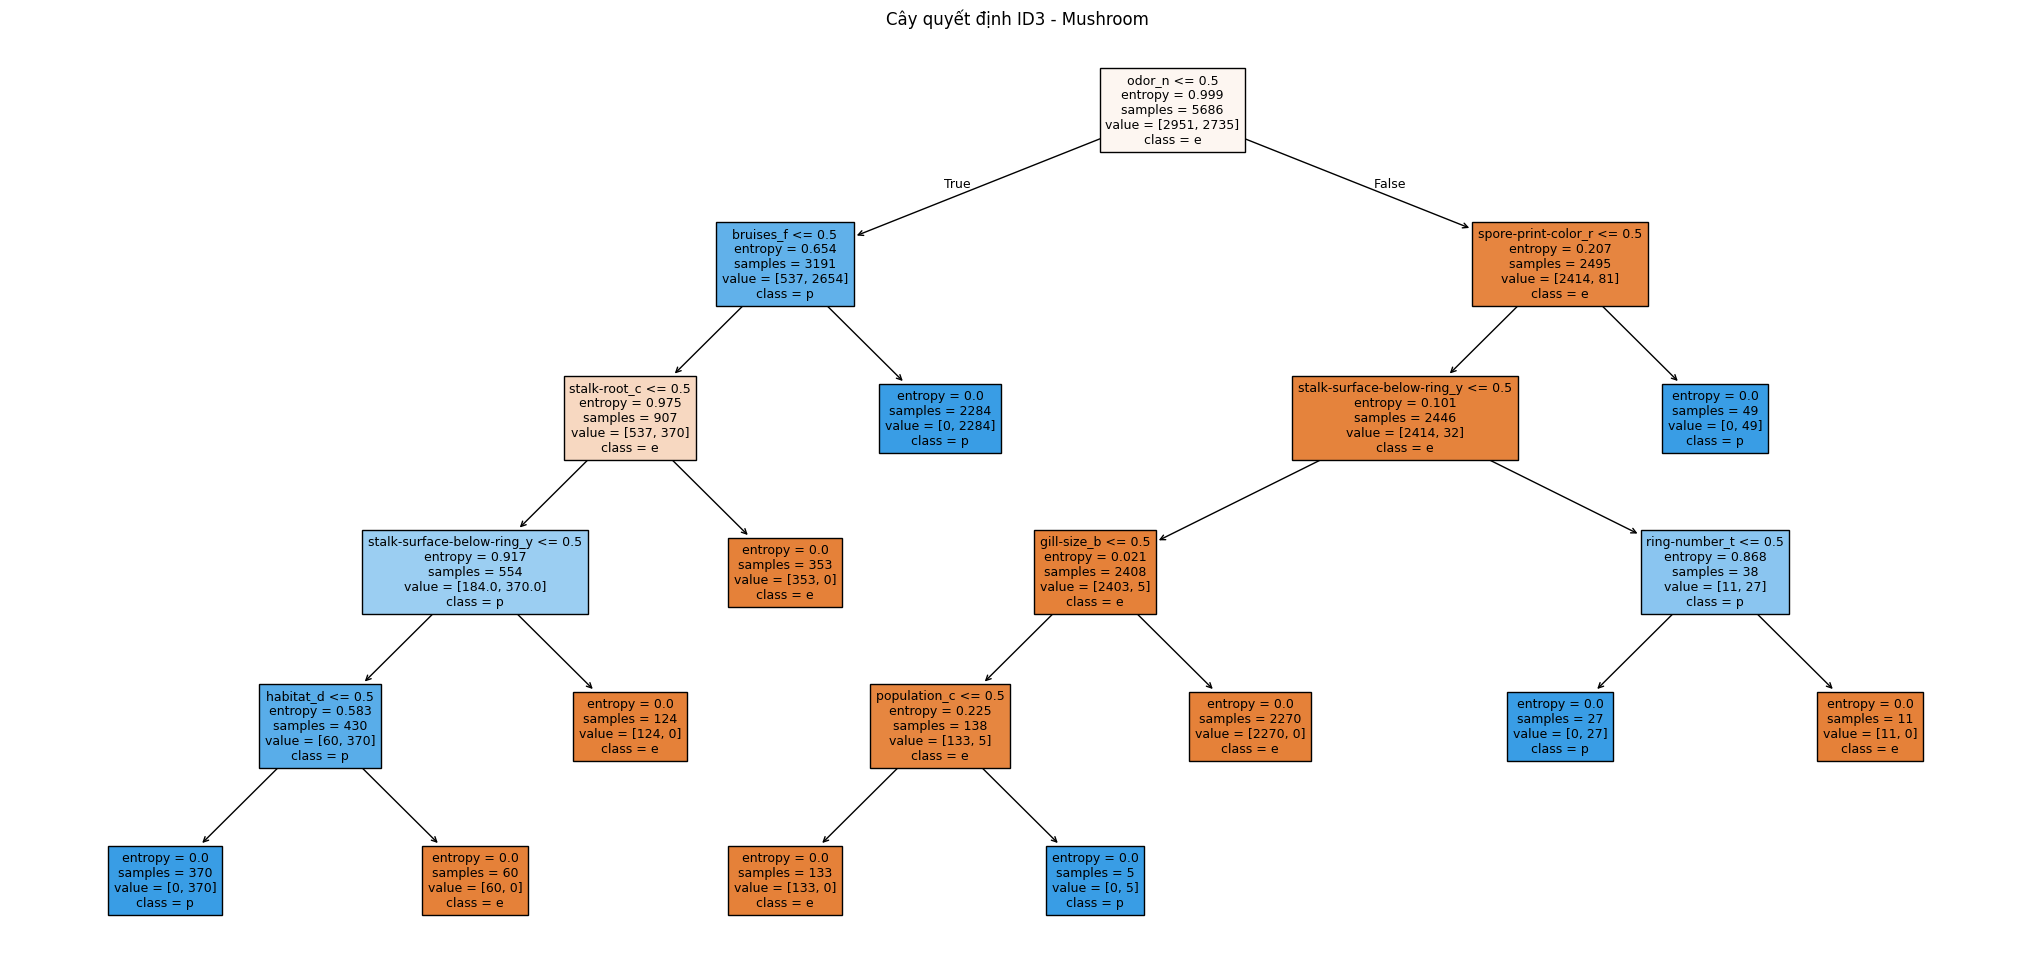

In [6]:
print("Dương Đại Phát - 6451071058")
fig, ax = plt.subplots(figsize=(26, 12))
tree.plot_tree(clf_id3, filled=True, fontsize=9,
               feature_names=features_onehot.columns, class_names=clf_id3.classes_)
plt.title("Cây quyết định ID3 - Mushroom")
plt.savefig('mushroom_tree_id3.png', dpi=100, bbox_inches='tight')
plt.show()

## Câu 8: Xây dựng cây quyết định CART (`criterion='gini'`)

Dương Đại Phát - 6451071058
CART Accuracy: 1.0
Report:
               precision    recall  f1-score   support

           e       1.00      1.00      1.00      1257
           p       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



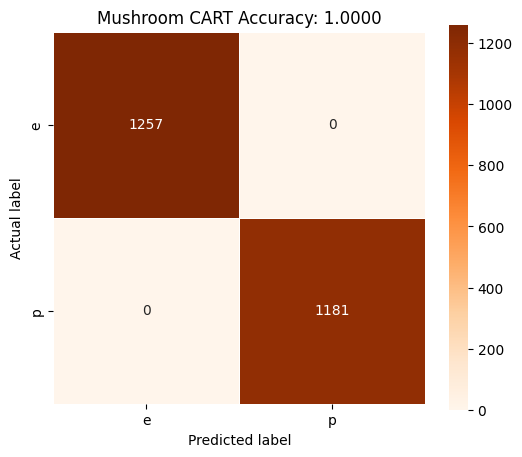

In [7]:
print("Dương Đại Phát - 6451071058")
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
clf_cart.fit(X_train, y_train)
cart_pred = clf_cart.predict(X_test)

cart_score = metrics.accuracy_score(y_test, cart_pred)
print("CART Accuracy:", cart_score)
print("Report:\n", metrics.classification_report(y_test, cart_pred))

cart_cm = metrics.confusion_matrix(y_test, cart_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cart_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Oranges',
            xticklabels=clf_cart.classes_, yticklabels=clf_cart.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Mushroom CART Accuracy: {cart_score:.4f}', size=12)
plt.show()

Dương Đại Phát - 6451071058


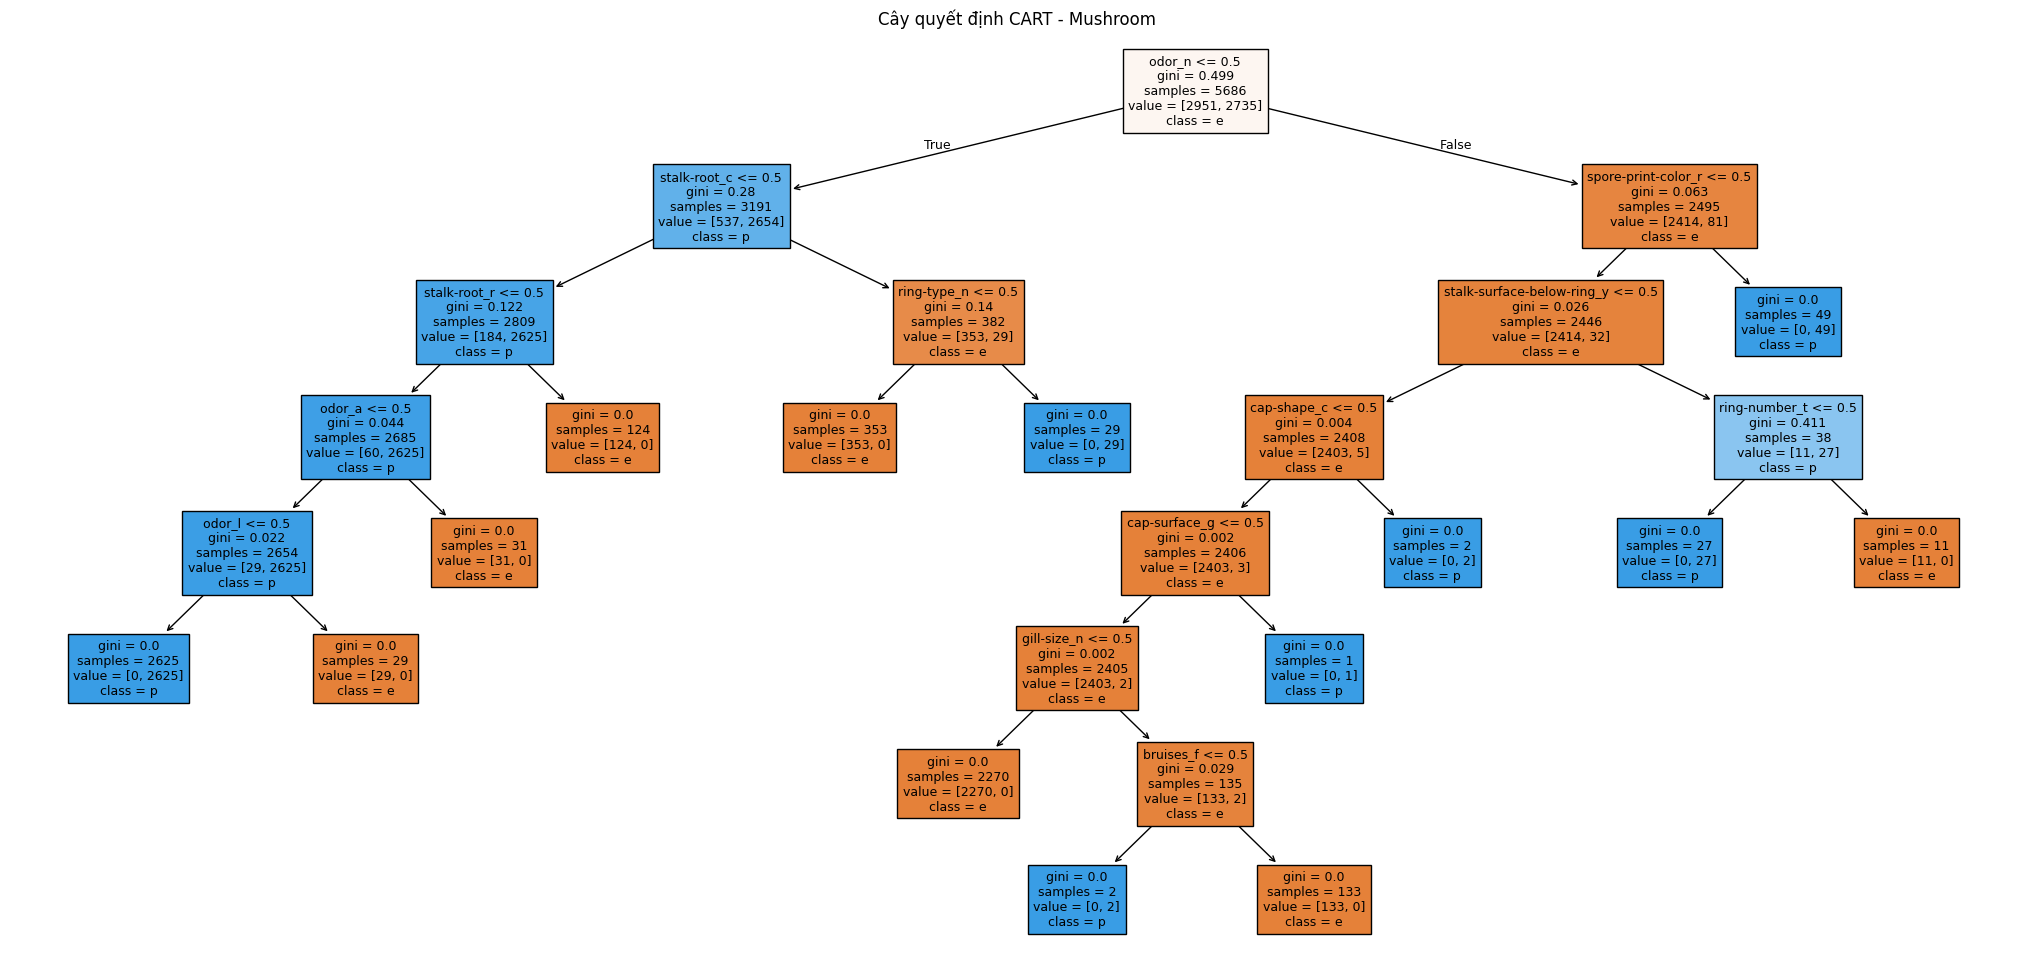

In [8]:
print("Dương Đại Phát - 6451071058")
fig, ax = plt.subplots(figsize=(26, 12))
tree.plot_tree(clf_cart, filled=True, fontsize=9,
               feature_names=features_onehot.columns, class_names=clf_cart.classes_)
plt.title("Cây quyết định CART - Mushroom")
plt.savefig('mushroom_tree_cart.png', dpi=100, bbox_inches='tight')
plt.show()

## Câu 9: Xây dựng mô hình Naïve Bayes (`GaussianNB`)

Dương Đại Phát - 6451071058
Naive Bayes Accuracy: 0.9643150123051681
Report:
               precision    recall  f1-score   support

           e       1.00      0.93      0.96      1257
           p       0.93      1.00      0.96      1181

    accuracy                           0.96      2438
   macro avg       0.97      0.97      0.96      2438
weighted avg       0.97      0.96      0.96      2438



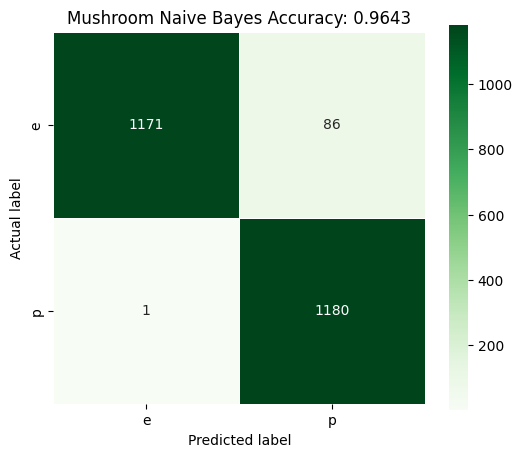

In [9]:
print("Dương Đại Phát - 6451071058")
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print("Naive Bayes Accuracy:", bayes_score)
print("Report:\n", metrics.classification_report(y_test, bayes_pred))

bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(bayes_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Greens',
            xticklabels=gnb.classes_, yticklabels=gnb.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Mushroom Naive Bayes Accuracy: {bayes_score:.4f}', size=12)
plt.show()

## Câu 10: So sánh kết quả của các mô hình

In [10]:
print("Dương Đại Phát - 6451071058")
results = []
for name, pred in [("ID3 (Entropy)", id3_pred), ("CART (Gini)", cart_pred), ("Naive Bayes", bayes_pred)]:
    results.append({
        "Mô hình": name,
        "Accuracy": round(metrics.accuracy_score(y_test, pred), 4),
        "Precision (Macro)": round(metrics.precision_score(y_test, pred, average='macro'), 4),
        "Recall (Macro)": round(metrics.recall_score(y_test, pred, average='macro'), 4),
        "F1-score (Macro)": round(metrics.f1_score(y_test, pred, average='macro'), 4),
    })

df_compare = pd.DataFrame(results)
print(df_compare.to_string(index=False))
print("\nNhận xét: Cả ID3 và CART đều đạt độ chính xác tuyệt đối 100% (1.0000) trên tập kiểm thử Mushroom với cây có độ sâu nhỏ, trong khi Naive Bayes (GaussianNB) đạt ~96.43%.")

Dương Đại Phát - 6451071058


      Mô hình  Accuracy  Precision (Macro)  Recall (Macro)  F1-score (Macro)
ID3 (Entropy)    1.0000             1.0000          1.0000            1.0000
  CART (Gini)    1.0000             1.0000          1.0000            1.0000
  Naive Bayes    0.9643             0.9656          0.9654            0.9643

Nhận xét: Cả ID3 và CART đều đạt độ chính xác tuyệt đối 100% (1.0000) trên tập kiểm thử Mushroom với cây có độ sâu nhỏ, trong khi Naive Bayes (GaussianNB) đạt ~96.43%.
